# 当代人工智能 · 实验二

姓名：庞毅飞　学号：10245501420　仓库链接：https://github.com/pyf060502-glitch/Lab-of-Contemporary-AI/tree/main/lab2

## Quiz1：迷宫最短路径搜索

### 1. 实验目标与设计

本次实验中，我先比较 BFS、Dijkstra 和三种启发函数下的 A*，再以曼哈顿 A* 为基准，比较单向、双向与反向 Dijkstra/BFS 混合搜索。通过最短性校验及扩展数、耗时、峰值内存，分析启发函数、搜索方向和队列开销。

- **地图准备：**
  先生成 39 张地图，其中 24 张可达、15 张无解，规模为 20×20、50×50、100×100，覆盖开放区、蛇形走廊、绕路、隔墙及 10%/25%/40% 随机障碍。每个随机配置固定三个种子，让各算法使用同一批数据。

- **验证与测量：**
  各组合预热一次，时间测 7 次、内存独立测 3 次，取中位数后跨图等权平均。扩展数排除终点及过期项，双向求和；计时含相遇检测和拼接，不含输入与校验。tracemalloc 计搜索新增分配及路径，不含地图，非进程总内存。

### 2. 算法原理与实现过程

- **建立搜索算法：**
  状态表示为坐标 (row,col)，本题仅允许上下左右移动，路径代价 $g$ 每步增加 1，A* 按 $f=g+h$ 搜索。我分别采用曼哈顿 $h_M=|d_r|+|d_c|$、欧几里得 $h_E=\sqrt{d_r^2+d_c^2}$ 和切比雪夫 $h_C=\max(|d_r|,|d_c|)$，三者满足 $h_C\leq h_E\leq h_M$，且均不超过真实剩余代价，均可采纳且一致；曼哈顿下界更强，但仍忽略障碍。Dijkstra 即 $h=0$ 的 A*，按 $g$ 排序，BFS 使用 FIFO，单位边权下二者搜索层次相近。实现时维护距离、父节点和开放表，堆按 $f$、$g$、坐标依次排序，邻居顺序为上、下、左、右，最终沿父链恢复路径。

- **加入双向与混合搜索：**
  我让正向先行，两侧交替扩展一个有效节点，各自维护状态。相遇时用两侧距离之和更新候选代价 $\mu$，最后拼接父链。$L_f$、$L_b$ 是有效队首给出的完整路径代价下界，满足 $\mu\leq\max(L_f,L_b)$ 或一侧队列耗尽时结束，不直接相加两个独立 $f$ 值。回归用例首次连接 26 步，继续搜索才得到最短的 24 步，因此不能首次相遇就停止。

- **示例路径的形成：**
  对题目给定的 5×5 地图，从 $S=(0,0)$ 出发；依次取 (0,1)、(0,2)、(1,2)、(1,3)、(1,4)、(2,4)，最后到 $E=(3,4)$。沿该最短路径，$g$ 依次为 0,1,2,3,4,5,6,7，曼哈顿 $h$ 为 7,6,5,4,3,2,1,0，$f$ 均为 7。搜索会同时考虑其他候选格；障碍 (0,3) 不入队，每次发现更小的 $g$ 就更新距离和父节点，再将候选格压入堆。终点作为有效最小项出队后，沿父链逆向回溯并反转，得到上述 7 步路径。这里列的是最终父链，不是全部节点的出队顺序。


### 3. 结果展示与对照分析

完成搜索后，我用独立 BFS 核对最短距离，并检查端点、连续移动、障碍及输入是否被修改。两轮共 351 项地图/策略组合均通过检查，结果如下。

**表1　初始比较（v1.0）。**

| 算法 | 平均扩展节点 | 耗时/ms | 峰值内存/KiB |
| :--- | ---: | ---: | ---: |
| BFS | 2768.8 | 6.487 | 433.7 |
| Dijkstra | 2768.8 | 10.468 | 352.0 |
| A* 曼哈顿 | 2396.9 | 9.624 | 318.9 |
| A* 欧几里得 | 2683.4 | 10.389 | 354.7 |
| A* 切比雪夫 | 2697.9 | 10.800 | 353.4 |

**表2　单向与双向对照（v1.1）。**

| 算法 | 平均扩展节点 | 耗时/ms | 峰值内存/KiB |
| :--- | ---: | ---: | ---: |
| 单向曼哈顿 A* | 2396.9 | 5.898 | 319.2 |
| 双向曼哈顿 A* | 2161.1 | 6.662 | 298.8 |
| A* + Dijkstra | 2284.9 | 6.858 | 302.3 |
| A* + BFS | 2285.2 | 6.160 | 300.7 |

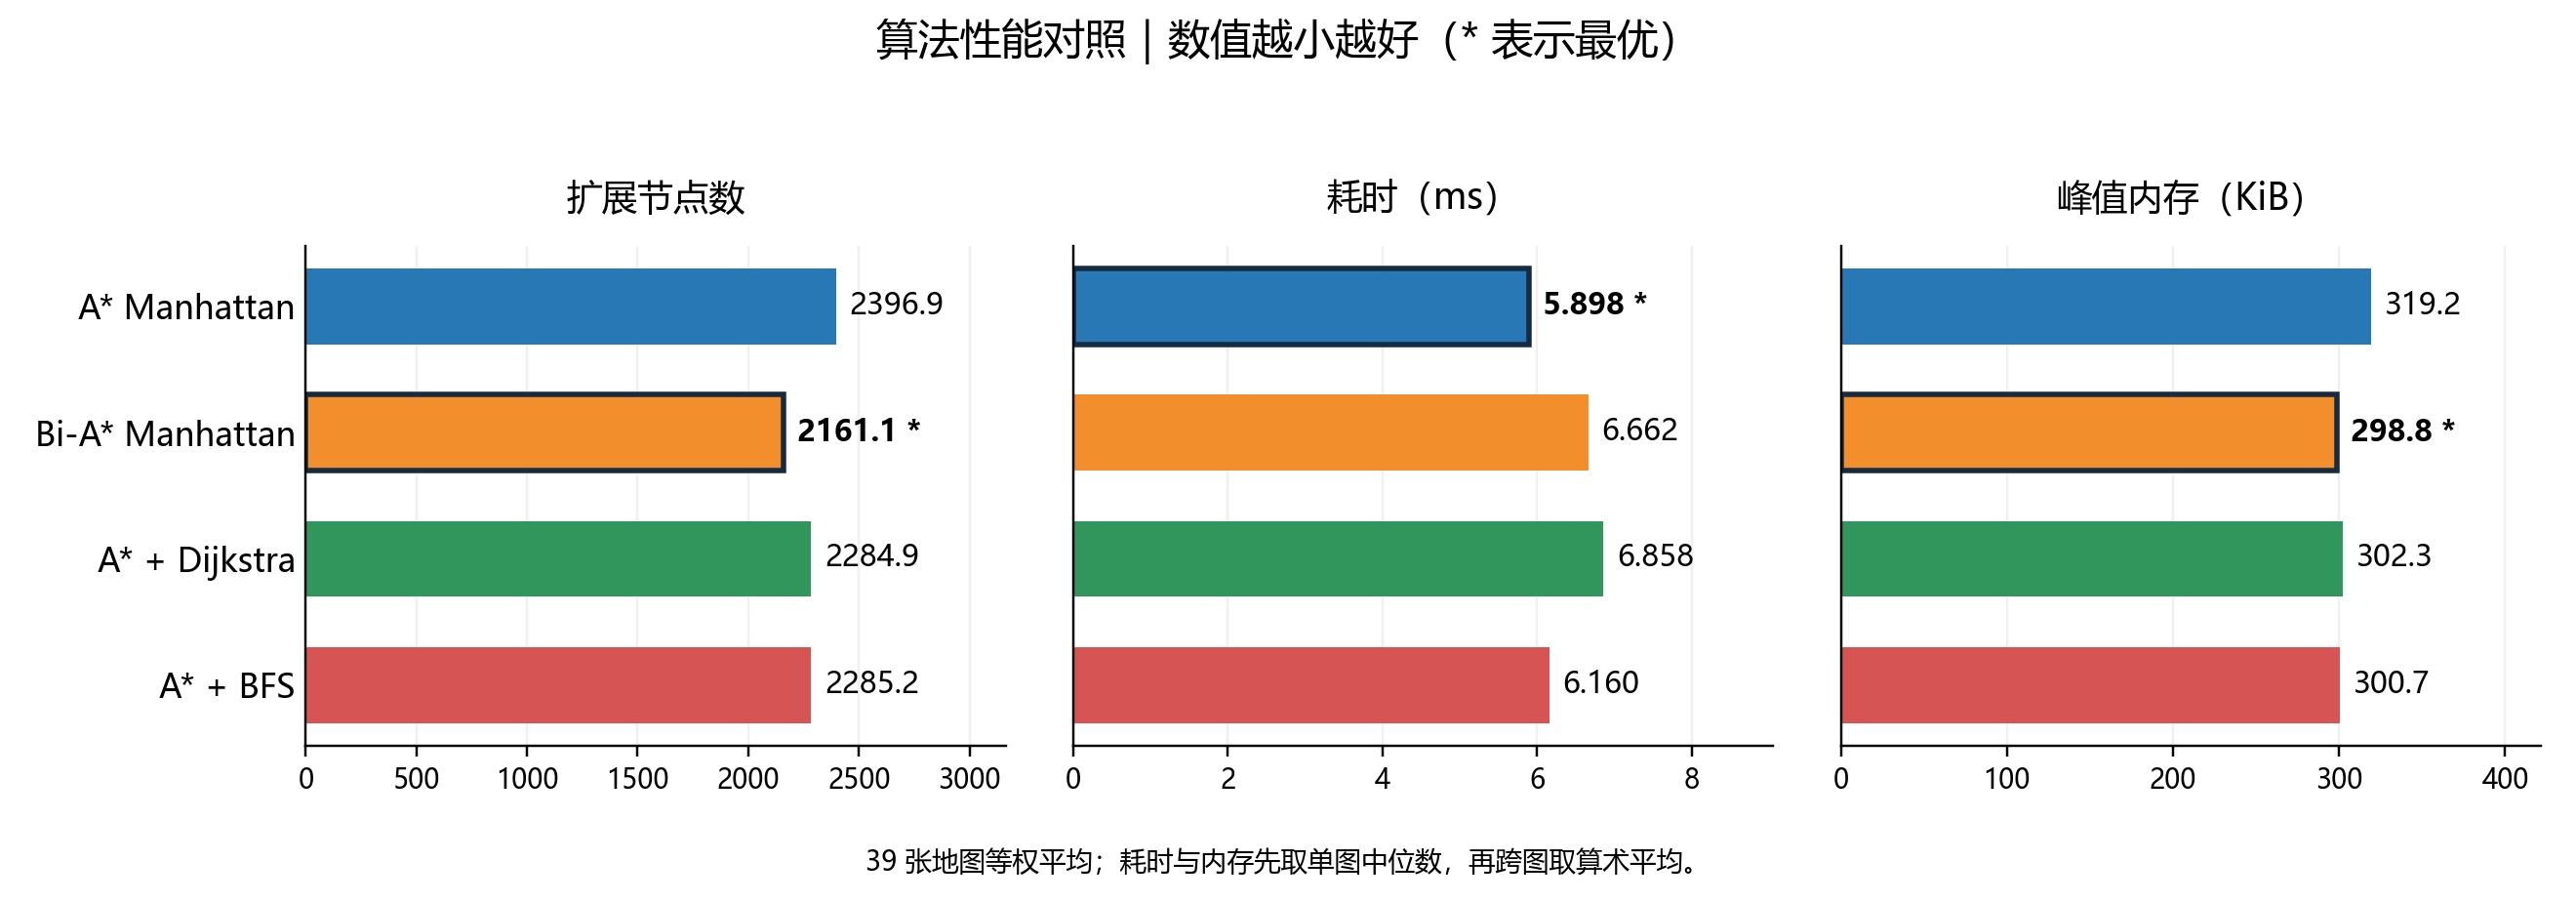

将结果与理论对照后，我发现 v1.0 的 39 张地图均满足“曼哈顿 A*$\leq$欧几里得 A*$\leq$切比雪夫 A*$\leq$Dijkstra”的扩展数量顺序，与启发下界越强、通常搜索越少的预期一致，但具体扩展量也受平局规则影响。BFS 与 Dijkstra 的扩展数几乎相同，符合单位边权下按距离逐层搜索的特点；BFS 使用普通队列而非堆，所以本次耗时更低。理论保证最短路径，并不保证 A* 一定比 BFS 快；峰值内存还取决于 Python 容器和状态保存方式，不能仅由扩展数推断。

基于表1，我进一步围绕曼哈顿 A* 进行第二轮比较。从表2和图1看，单向 A* 最快；双向 A* 的扩展数下降 9.8%、内存下降 6.4%，但耗时增加 13.0%；混合 BFS 比混合 Dijkstra 快 10.2%。这说明减少节点并不一定更快，堆操作、双侧状态维护和相遇检测也有开销。两轮代码和测量批次不同，因此只在各轮内部比较绝对耗时。

### 4. 深入分析与独立思考

我又按可达性和地图结构查看结果：可达图中，单向与双向 A* 平均扩展 2902.1、2928.9 个节点；无解图中为 1588.5、932.5。随机图上双向由 2032.3 降至 1260.7，蛇形走廊却由 2176.3 增至 4236.3。因此，总体优势主要来自部分随机及无解场景，不能认为每类地图都更优。当前停止界在狭长路径上可能让双方覆盖大量相同坐标；开放图中许多节点的 $f$ 相同，较小 $g$ 优先也会扩大搜索范围。

另外，单位边权下，两种混合策略扩展层次接近，BFS 队列操作更轻，因而相对 Dijkstra 更快。后续可以保持最优性，分别调整平局规则、方向调度和双向停止界，区分启发质量与实现开销，并增加随机种子检验结论是否稳定。

### 5. 总结

在 v1.0 中，BFS 的耗时最低，曼哈顿 A* 的扩展数和峰值内存最低；三种 A* 中，曼哈顿启发更能减少搜索扩展。在 v1.1 的四组策略中，追求运行速度时可选单向曼哈顿 A*，关注总体扩展和内存时可考虑双向曼哈顿 A*。具体选择仍需结合地图结构、终止规则和资源目标，本批数据中没有三项指标全面领先的策略。

## Quiz2：加权地形最小代价搜索

### 1. 实验目标与设计

本次实验中，我将迷宫改为不同进入代价的地形，先比较 Dijkstra、修正曼哈顿 A* 和最小权重缩放 A*，再加入 2、4 地标 A*，观察更强的启发信息能否减少搜索，以及这些收益是否足以抵消预处理和查表开销。

- **数据与测量：** 使用同一批 105 张地图，其中 74 张可达、31 张无解；含 20×20、50×50、100×100 地图及边界用例，覆盖均匀地形、低价绕路、障碍和三档随机密度，权重组合为 1/3/8、2/5/9、3/6/9，每个随机配置固定三个种子。各组合预热一次，计时 7 次、内存另测 3 次，取单图中位数再等权平均。v2.1 分别记录预处理、查询及总成本，总耗时逐次测量，不将阶段中位数相加。tracemalloc 总峰值含地形矩阵和保留索引，不含预载输入，非进程总内存。扩展数仅计查询的有效非终点节点，预处理扩展另记。

### 2. 算法原理与实现过程

- **代价与基本启发：** 只能上下左右移动，从 $u$ 进入 $v$ 时增加 $v$ 的权重；起点初始不收费，再次进入 S 使用其地形权重，进入终点免费。找到目标后返回最小总代价，无解返回 -1。普通曼哈顿距离 $d$ 在终点相邻处估计为 1，实际却为 0，会高估。因此改用 $h_1=\max(d-1,0)$，再以非终点最小权重 $c_{\min}$ 缩放为 $h_s=c_{\min}\max(d-1,0)$，Dijkstra 对应 $h=0$。任何到终点的路径至少走 $d$ 步，其中至少 $d-1$ 步进入非终点，每步代价不小于 $c_{\min}$，故 $h_s$ 不超过真实剩余代价；非终点权重至少为 1 时，$h_1$ 同样成立。出现非终点零权时，$h_1$ 置 0，$h_s$ 也自然为 0。堆统一按 $f=g+h$、$g$、坐标依次排序，邻居顺序为上、下、左、右，维护距离和父链恢复路径。

- **地标启发：** 按地图内部四分位锚点选择可通行格，2 地标是 4 地标的前两个，不针对查询起终点选点。对每个地标 $L$，分别计算 $d(L,n)$ 和 $d(n,L)$，使用 $h_L(n)=\max(0,d(L,t)-d(L,n),d(n,L)-d(t,L))$，只保留均有限的距离差，最终 $h=\max(h_s,h_{L_1},\ldots,h_{L_k})$，保持可采纳性与一致性。进入权重使边权不对称，反向 $v\to u$ 应收取原图进入 $v$ 的代价，不能套用无向绝对值公式。每次固定起终点查询均重新预处理，因终点免费规则随终点改变，不直接复用旧表；预处理不读取参考答案。

- **示例代价累计：**
  题目示例的一条最优路径为 (0,0)→(1,0)→(2,0)→(3,0)→(3,1)→(3,2)→(4,2)→(4,3)→(4,4)。起点 $g=0$，之后进入七个权重为 1 的格子，累计代价依次为 1,2,3,4,5,6,7；最后进入 E 增加 0，总代价仍为 7。由此可见，8 次移动不等于代价 8，本题应累计进入权重，而非直接统计步数。


### 3. 结果展示与对照分析

两轮共 735 项地图/算法组合均通过独立反向 Dijkstra、路径累计代价和合法性检查，题目示例均返回 7；另用 Bellman-Ford 检查小地图、地标距离及启发下界。

**表3　加权地形比较（v2.0）。**

| 算法 | 查询扩展数 | 耗时/ms | 峰值内存/KiB |
| :--- | ---: | ---: | ---: |
| Dijkstra | 2663.0 | 4.415 | 391.8 |
| 修正曼哈顿 A* | 2641.8 | 4.862 | 392.4 |
| 缩放 A* | 2623.4 | 4.996 | 396.3 |

**表4　地标对照（v2.1，预处理与查询均计入总成本）。**

| 算法 | 查询扩展数 | 预处理/ms | 查询/ms | 总耗时/ms | 总峰值/KiB |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Dijkstra | 2663.0 | 0.714 | 2.709 | 3.424 | 194.0 |
| 缩放 A* | 2623.4 | 0.713 | 3.516 | 4.245 | 196.0 |
| 地标 A*（2） | 2456.6 | 11.416 | 5.193 | 16.642 | 439.3 |
| 地标 A*（4） | 1751.6 | 22.599 | 4.896 | 27.532 | 662.5 |

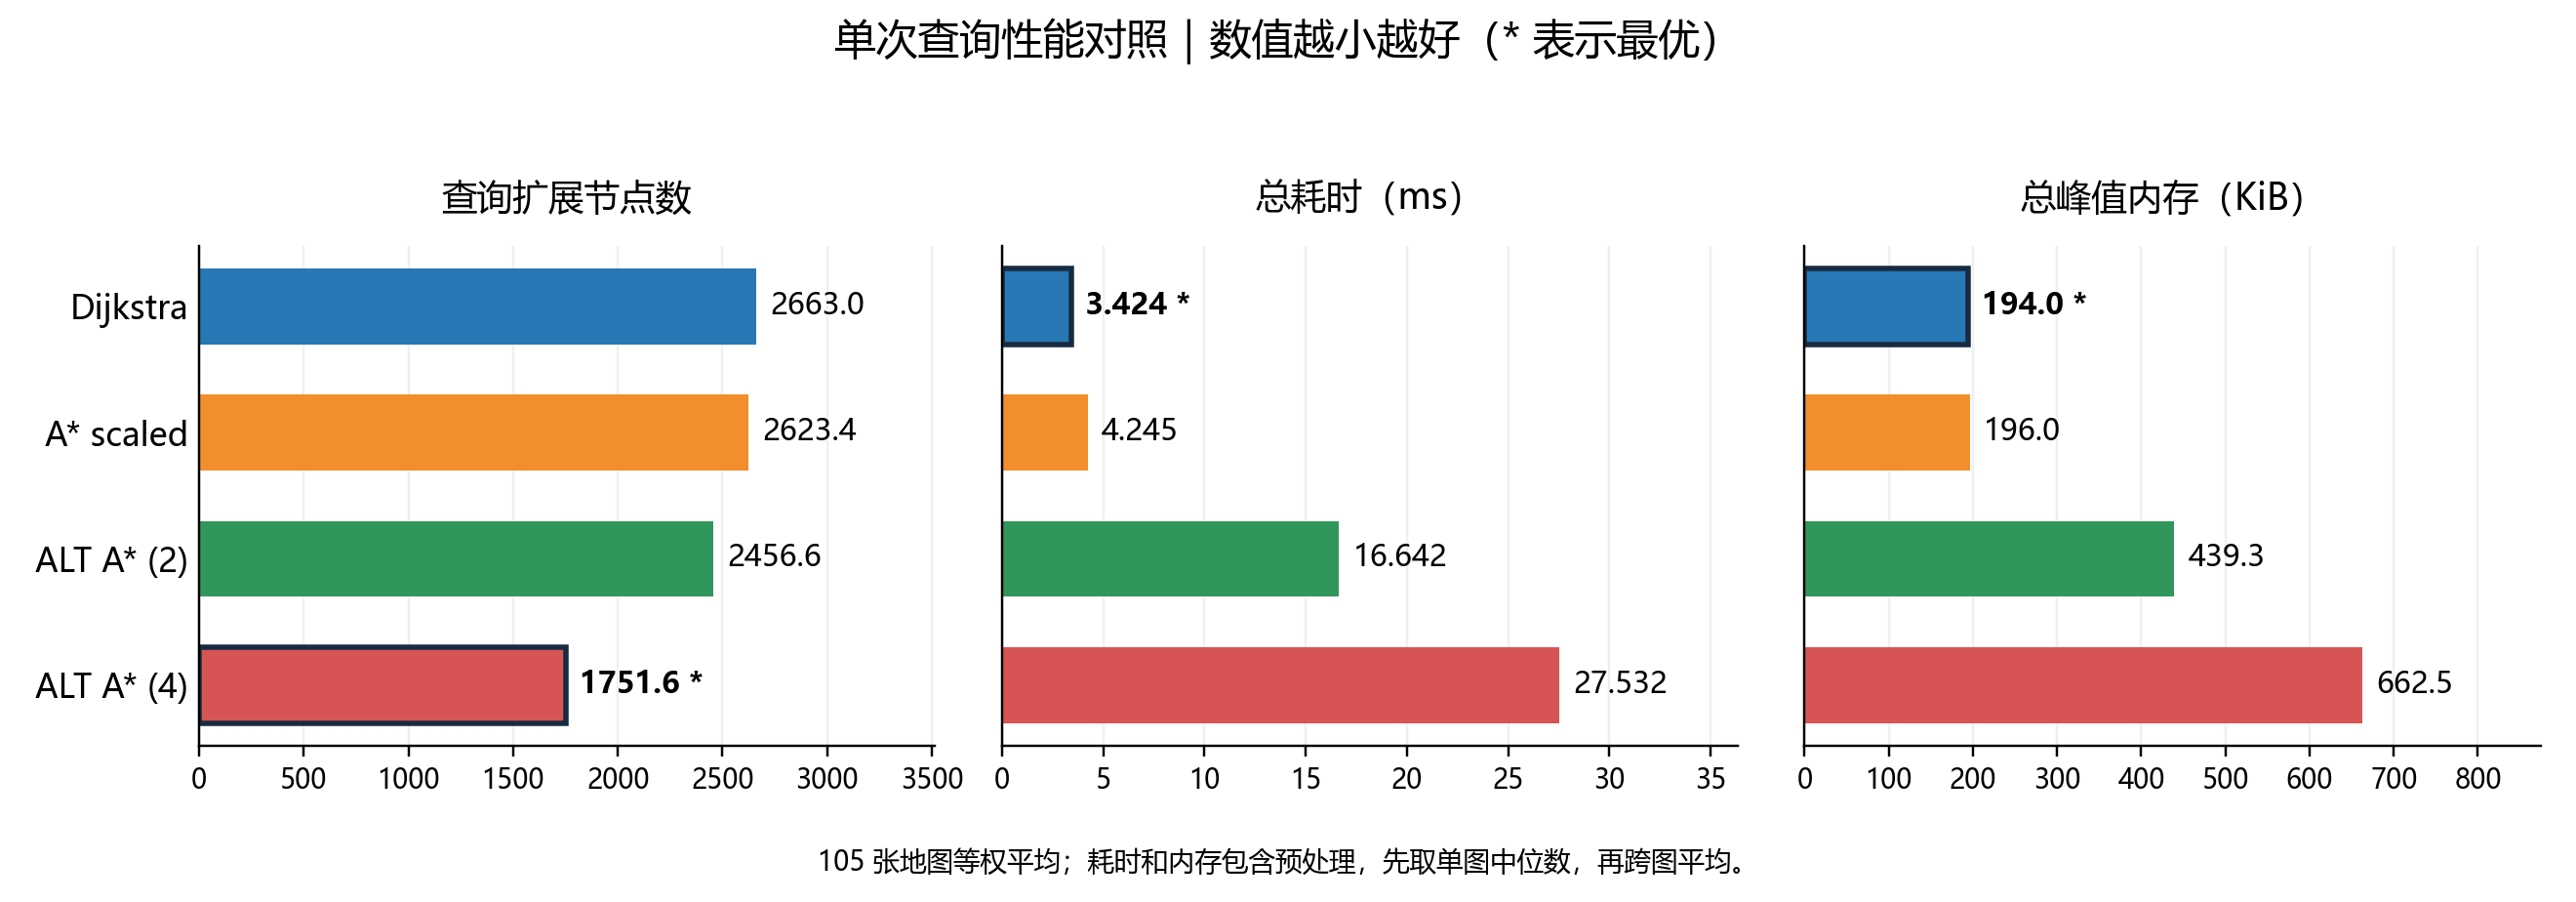

从表3看，缩放 A* 的扩展数最少，但 Dijkstra 更快、内存更低。从表4和图2看，4 地标相对缩放 A* 少扩展 33.2%，但总耗时由 4.245 ms 增至 27.532 ms，总峰值由 196.0 KiB 增至 662.5 KiB。地标预处理耗时明显增加，甚至只看查询，4 地标的 4.896 ms 仍高于缩放 A* 的 3.516 ms，说明查表与计算下界也有成本。两轮使用的数据表示不同，耗时和内存只在各轮内部比较。

### 4. 深入分析与独立思考

我进一步结合地形分析：最小权重只反映全局下界，难以识别局部昂贵区域，因此缩放后的搜索收益可能有限；均匀地形中，许多节点的 $f$ 相同，较小 $g$ 优先也会影响访问数量。地标加入地图距离信息，且 $h_4\geq h_2\geq h_s$，但更多地标不意味着更快。4 地标的索引构建平均另扩展 27422.1 个节点，只展示查询扩展数会掩盖实际工作量。

因此，本轮固定终点的单次查询应比较总成本，不能只凭查询节点减少就认定地标更优。后续可优化选点、距离表及下界计算，并在处理好免费终点语义后再研究多查询复用；本次查询阶段仍较慢，不能直接断言摊薄预处理后必然加速。

### 5. 总结

在 v2.0 中，修正与缩放启发保证了免费终点下的可采纳性，缩放 A* 更能减少扩展；在 v2.1 中，4 地标提供了更强的查询引导，但本批单次查询的总耗时和内存仍以 Dijkstra 最低。选择启发函数需要同时考虑估计质量、计算成本及使用场景。

## Quiz3：极大极小博弈树与 Alpha-Beta 剪枝

### 1. 实验目标与设计

本次实验中，我先以完整 Minimax 为基准，再比较 Alpha-Beta 的原始、反向和固定随机访问顺序，观察最佳得分、搜索量与运行开销。输入共 40 棵树：27 棵规则树采用分支数 $b=2,3,4$、深度 $d=3,5,7$，每组 3 个固定种子；另含 6 棵非规则树和 7 棵示例、边界树。根深度为 0，深度按边数计算，规则随机叶分数取自 [-100,100]。

每组预热 1 次，计时 7 次、内存独立测 3 次，先取单树中位数再跨树等权平均。访问数含根、内部节点和叶节点，叶求值另计；节点节省率逐树计算 $1-N_{\mathrm{AB}}/N_{\mathrm{Minimax}}$ 后平均。顺序在测量前准备并固定，计时含搜索和统一计数，不含读取、建树与校验；tracemalloc 记录搜索新增分配，不含预载树。


### 2. 算法原理与实现过程

状态由当前节点及 MAX/MIN 角色表示，内部节点保存 children，叶节点保存 value；根为 MAX，角色逐层交替。Minimax 完整递归，MAX 取最大值、MIN 取最小值。Alpha-Beta 从 $\alpha=-\infty$、$\beta=+\infty$ 开始，MAX 更新 $\alpha$、MIN 更新 $\beta$；当 $\alpha\geq\beta$ 时，跳过剩余子节点。正式接口仍从左到右，另两组只改变访问顺序；各组均搜索到真实叶节点，不使用缓存。

题目示例中，左侧首个 MAX 由 3、5 返回 5，使其 MIN 父节点 $\beta=5$；随后第二个 MAX 读到 6，$\alpha=6\geq\beta$，跳过 9。此处返回 6 已足以证明该分支不会被父节点选中，完整子树值实际为 9。左侧返回 5 后，根 $\alpha=5$；右侧两个 MAX 得到 9、2，MIN 返回 2，根最终取 $\max(5,2)=5$。Minimax 访问 15 个节点、求值 8 个叶；原始 Alpha-Beta 为 14、7，有效剪枝 1 次。两处 [6,9] 按独立子树展开。


### 3. 结果展示与对照分析

160 组得分均与独立迭代后序求值及数据参考答案一致；5 项测试还覆盖 6561 种小树叶分数组合、角色与相等边界。表5为全部 40 棵树的平均结果。

**表5　v3.0 四组策略对照。**

| 策略 | 访问节点 | 叶求值 | 节省率/% | 耗时/ms | 峰值/KiB |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Minimax | 2082.7 | 1530.1 | 0.00 | 0.5749 | 3.15 |
| Alpha-Beta（原始） | 462.0 | 288.4 | 38.83 | 0.2014 | 3.96 |
| Alpha-Beta（反向） | 474.2 | 297.5 | 44.80 | 0.2055 | 3.91 |
| Alpha-Beta（随机） | 467.3 | 292.4 | 44.19 | 0.2025 | 3.86 |

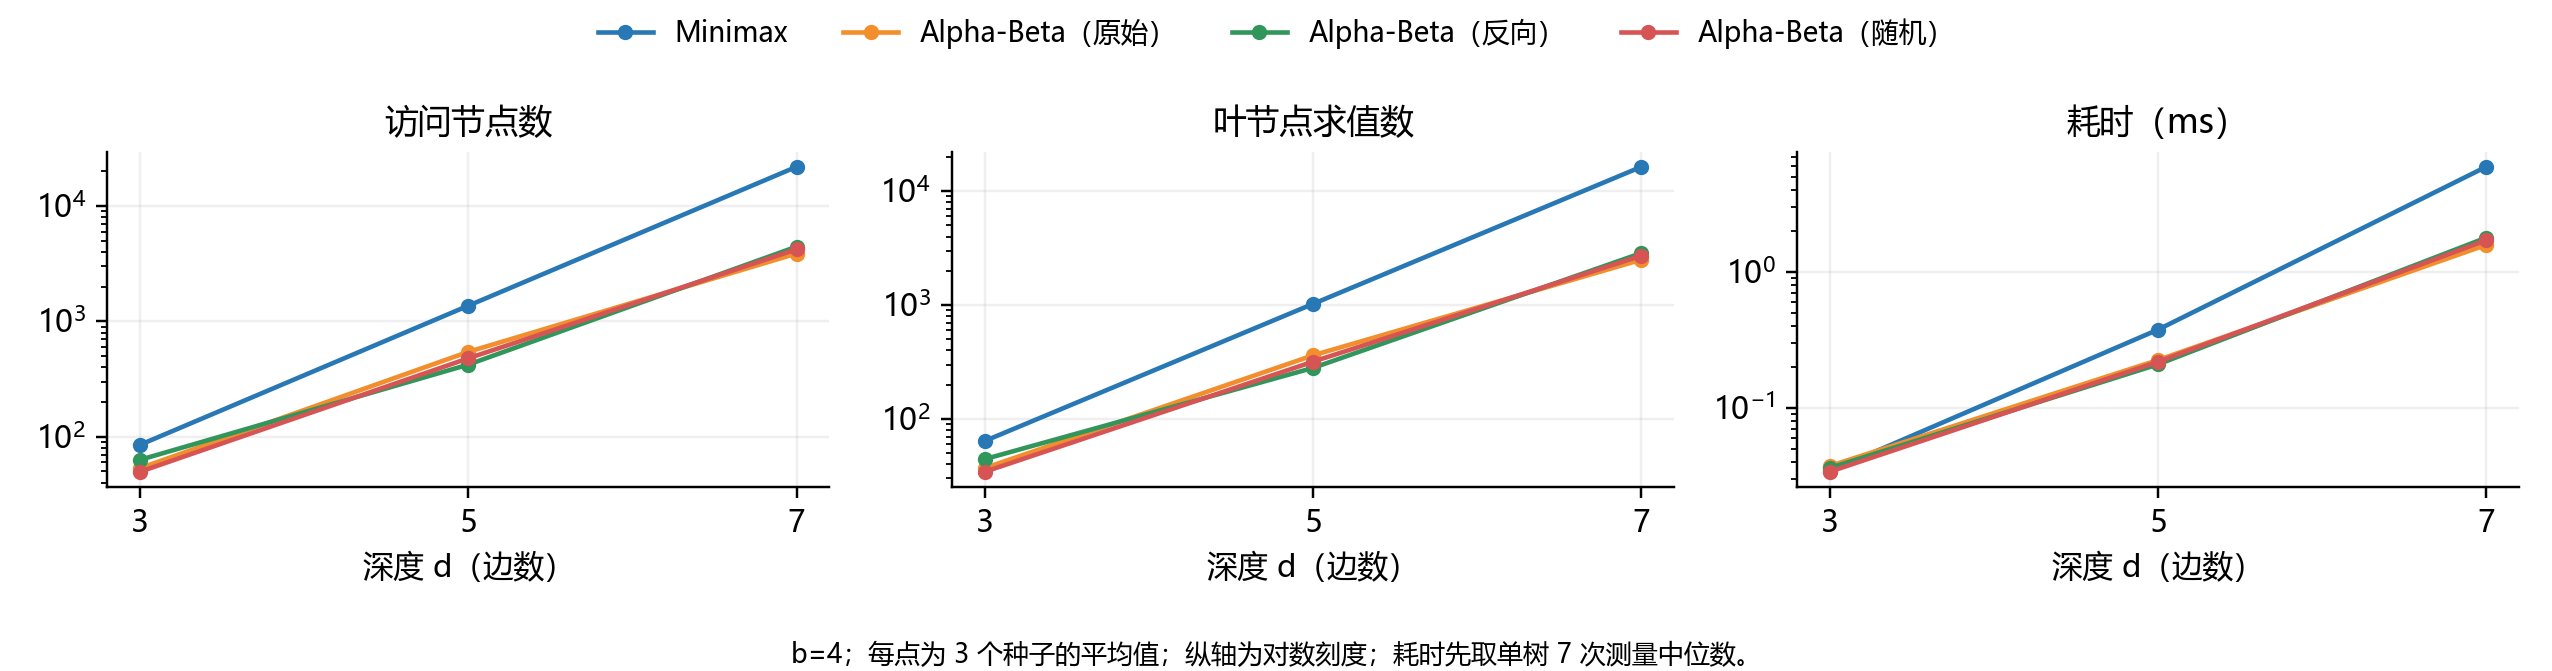

从表5看，原始 Alpha-Beta 的平均访问量由 2082.7 降至 462.0，耗时由 0.5749 ms 降至 0.2014 ms，约为 2.86 倍加速；峰值由 3.15 增至 3.96 KiB。三种 Alpha-Beta 的平均耗时接近。图3中，随深度增加，完整搜索的增长明显快于剪枝搜索；但在 $b=2$、$d=3$ 的小树上，原始 Alpha-Beta 为 0.0201 ms，Minimax 为 0.0156 ms，维护边界的开销超过了省下的搜索。

### 4. 深入分析与独立思考

访问顺序决定边界多早收紧，得分则保持不变。$b=3$ 时反向策略平均访问 339.9 个节点，少于原始的 433.2；$b=4$ 时原始为 1488.7，反向为 1640.9，说明反转并非稳定的好顺序。原始策略总体访问量最低，反向的逐树平均节省率却更高：前者更受大树访问量影响，后者让每棵树等权，因此两项排名可以不同。

剪枝效果也取决于结构和分数。单分支树各组均访问 8 个节点，无兄弟可剪；全相等树在 $\alpha=\beta$ 时仍能剪枝，访问量由 40 降至 20。有效剪枝次数只统计确有剩余孩子的截断，一次截断可能省去整棵大子树，故以访问量和叶求值量判断收益。规则树最差搜索量仍为 $O(b^d)$，理想顺序下约为 $O(b^{d/2})$；本次自然顺序的结果体现了顺序敏感性。两类算法都深度优先，工作空间主要随递归深度增长，剪掉大量节点也未必降低峰值内存。

### 5. 总结

本次四组策略均得到正确最佳得分。Alpha-Beta 在较大树上明显减少求值并加速，原始顺序在本批总体访问量和耗时上最低；不同顺序各有适用输入，应结合树深、分支数和分数分布分析剪枝收益。


## Quiz4：竞争环境下的宝藏分配

### 1. 实验目标与设计

本次实验中，我先用 A* 计算移动代价，再将四个宝藏的竞争分配建模为博弈，比较 Minimax 与原始、反向、即时收益排序的 Alpha-Beta。在题目 7×7 地图上分别搜索 $H=2$、$H=4$，并用途经宝藏、负收益、平局、加权绕路和位置更新五张小地图检查规则，共得到 48 组结果。$H$ 按单次玩家行动计数，$H=2$ 为双方各一次，$H=4$ 为完整四次行动。

各组合预热一次；耗时测 7 批，每批搜索 200 次后折算单次时间，再取中位数；内存独立单次测 3 次取中位数。访问数含根与叶，叶求值另计，节省率相对同图同 $H$ 的 Minimax。A* 预处理单独测量，博弈计时包含状态转移、排序和计数；输入、参考求值及序列恢复在计时外。tracemalloc 记录新增分配，不含预载地图和距离矩阵。

### 2. 算法原理与实现过程

只能上下左右移动，进入数字格支付其权重，进入 A/B/T 格支付 1，起点初始不收费。本题目标格不免费，直接使用曼哈顿 $h=|d_r|+|d_c|$，因每步代价至少为 1，该下界可采纳且一致。A* 按 $f$、$g$、坐标依次排序，分别计算 30 个有序点对，得到表6。宝藏获取后地形不变，另一玩家不阻挡道路，因此整个博弈复用该矩阵。

**表6　A、B、T1～T4 的最小移动代价。**

| 出发 / 到达 | A | B | T1 | T2 | T3 | T4 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| A | 0 | 12 | 10 | 4 | 8 | 8 |
| B | 12 | 0 | 8 | 8 | 4 | 10 |
| T1 | 10 | 8 | 0 | 6 | 6 | 12 |
| T2 | 4 | 8 | 6 | 0 | 6 | 6 |
| T3 | 8 | 4 | 6 | 6 | 0 | 6 |
| T4 | 8 | 10 | 12 | 6 | 6 | 0 |

状态记为 $(\mathrm{pos}_A,\mathrm{pos}_B,\mathrm{mask},\mathrm{Score}_A,\mathrm{Score}_B,\mathrm{turn})$，mask 用四位表示剩余宝藏。当前玩家选择 $T_i$ 后增加 $\mathrm{Gain}=V_i-D[\mathrm{pos},T_i]$，仅更新自身位置、收益和该宝藏位，再切换玩家。途经其他宝藏不获取，负收益行动仍合法。到达 $H$ 或宝藏取完时返回 $U=\mathrm{Score}_A-\mathrm{Score}_B$，MAX 取大、MIN 取小。Alpha-Beta 从 $(-\infty,+\infty)$ 开始，$\alpha\geq\beta$ 时截断；反向策略倒序访问，收益排序让双方都按自身 $\mathrm{Gain}$ 降序、同分按编号访问。平局保留首个访问的最优行动。


### 3. 结果展示与对照分析

全部 48 组通过独立 Dijkstra 距离与路径代价检查、完整行动排列求值及数据参考答案核对；7 项测试另以 Floyd-Warshall、小值组合和随机有向代价验证寻路、状态转移和剪枝。每个首步单独用完整窗口求值，四组策略的精确分项值一致。以下均为题目主地图结果。

**表7　v4.0 决策与搜索性能；节点和叶求值均为单次搜索计数。**

| H | 策略 | 首步 | U | 访问节点 | 叶求值 | 节省率/% | 耗时/ms | 峰值/KiB |
| ---: | --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 2 | Minimax | T2 | -1 | 17 | 12 | 0.00 | 0.0206 | 2.89 |
| 2 | Alpha-Beta（原始） | T2 | -1 | 13 | 8 | 23.53 | 0.0175 | 2.89 |
| 2 | Alpha-Beta（反向） | T2 | -1 | 16 | 11 | 5.88 | 0.0209 | 2.89 |
| 2 | Alpha-Beta（收益排序） | T2 | -1 | 11 | 6 | 35.29 | 0.0188 | 3.00 |
| 4 | Minimax | T3 | 3 | 65 | 24 | 0.00 | 0.0970 | 4.93 |
| 4 | Alpha-Beta（原始） | T3 | 3 | 47 | 16 | 27.69 | 0.0740 | 4.93 |
| 4 | Alpha-Beta（反向） | T3 | 3 | 46 | 16 | 29.23 | 0.0756 | 4.95 |
| 4 | Alpha-Beta（收益排序） | T3 | 3 | 37 | 12 | 43.08 | 0.0748 | 4.93 |

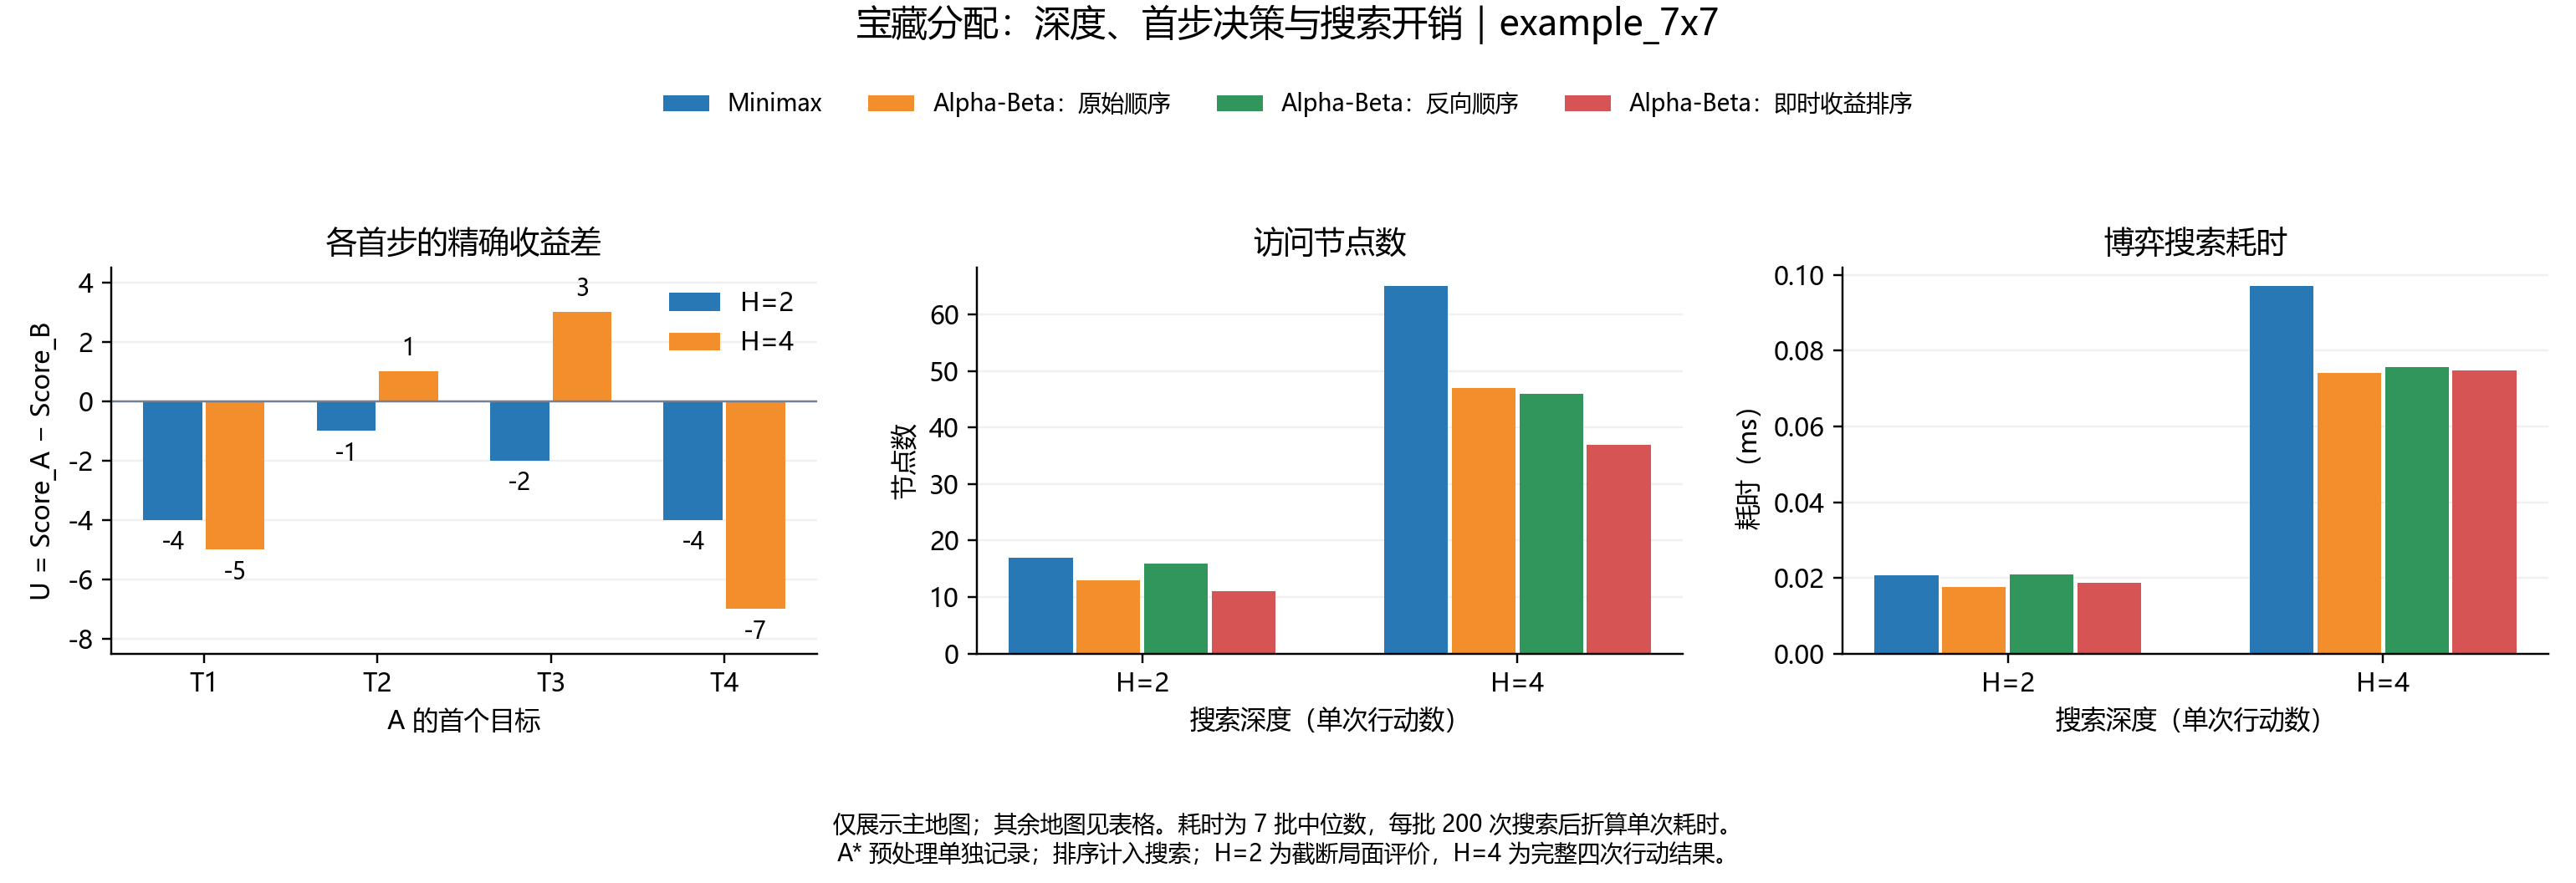

四组策略均在 $H=2$ 选择 T2、$U=-1$，在 $H=4$ 选择 T3、$U=3$。$H=2$ 时 A 取 T2，净收益 $6-4=2$，B 取 T3 得 $7-4=3$，故 $U=-1$；$H=4$ 的一条最优应对序列见表8。

**表8　$H=4$ 的最优行动与收益累计。**

| 行动 | 玩家与目标 | 移动代价 | 净收益 | 累计 U |
| ---: | --- | ---: | ---: | ---: |
| 1 | A→T3 | 8 | -1 | -1 |
| 2 | B→T1 | 8 | 1 | -2 |
| 3 | A→T2 | 6 | 0 | -2 |
| 4 | B→T4 | 12 | -5 | 3 |

### 4. 深入分析与独立思考

首先，深度改变了决策依据。$H=2$ 只评价前两次行动，尚未计入后续位置和移动成本；固定首步 T2 后搜索完整四次行动，最优对抗收益差为 1，而 T3 为 3。T3 的第一步净收益虽为 -1，却改变了后续宝藏分配，最终使 B 从 T1 前往 T4 支付 12、获得 -5。这解释了为何完整博弈选择 T3，也说明两种 $H$ 的 $U$ 分别属于截断局面与最终局面，决策质量应结合完整四次行动判断。

其次，即时收益排序与贪心决策不同。A 对 T2 的即时 $\mathrm{Gain}$ 为 2，对 T3 为 -1，排序会先考察 T2，最终仍依据完整回传值选择 T3。B 按自身 $\mathrm{Gain}$ 降序，是为了尽早找到压低 $U$ 的应对。该顺序在 $H=4$ 将访问量从 65 降至 37、叶求值从 24 降至 12；原始与反向分别访问 47、46 个节点，收益取决于边界建立的时机。

再次，减少访问不等于同比加速。收益排序与原始 Alpha-Beta 在 $H=4$ 的耗时分别为 0.0748、0.0740 ms，本次没有明显时间优势：树仅 65 个节点，计算 $\mathrm{Gain}$ 和排序的开销占比较高，两者测量样本也有重叠。各组峰值约 4.93～4.95 KiB，符合深度优先搜索主要保留递归路径的特点。


最后，静态地图使寻路与博弈可以分层。主图 A* 共扩展 331 个节点，预处理耗时中位数 0.4313 ms、峰值 32.22 KiB，超过单次博弈搜索开销；共享矩阵后，策略比较集中于决策本身。每次行动都从该玩家更新后的位置查距离；途经与已获取的宝藏格保持代价 1，保证矩阵在全局仍有效。

### 5. 总结

本次将加权寻路与对抗搜索连接起来，得到题目要求的两组首步与收益差。完整四次行动揭示了短期收益之外的位置和分配影响；即时收益排序能减少搜索量，但小树上的时间收益还取决于排序开销。有效的状态建模、正确的进入代价和完整回传共同决定了最终策略。
